# Altres Mètriques d'Anàlisi d'Espais (Nivell 1)
Aquest quadern explora mètriques i mètodes addicionals per avaluar l'estat actual i la viabilitat dels horaris i aules, més enllà de les preguntes base.

Les mètriques analitzades aquí són:
1. **Aforaments superats (Overcapacity)**: Sessions on el nombre d'alumnes supera la capacitat de l'aula assignada.
2. **Infrautilització d'espais**: Sessions on l'aula assignada és excessivament gran per al nombre d'alumnes (ex: menys del 30% d'ocupació).
3. **Càrrega lectiva per dia de la setmana**: Distribució de les hores de classe al llarg de la setmana per detectar dies sobrecarregats.
4. **Sessions sense aula per tipologia**: Anàlisi de quins tipus de classe (TE, PA, PLAB) tenen més problemes per trobar espai.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregar les dades i fusionar
sessions = pd.read_csv('sessions.csv')
aules = pd.read_csv('aules.csv')

# Unir sessions amb la informació de la seva aula assignada
df_merge = sessions.merge(aules, left_on='aula_partida', right_on='aula', how='inner')

print("Dades carregades i fusionades amb èxit.")


Dades carregades i fusionades amb èxit.


In [2]:
# 2. Aforaments superats (Overcapacity)
# Classes on els alumnes matriculats superen la capacitat de l'aula física
overcap = df_merge[df_merge['alumnes'] > df_merge['capacitat']]

print(f"Total de sessions on se supera l'aforament de l'aula: {len(overcap)}")

# Agrupar per titulació per veure qui ho pateix més
top_overcap = overcap.groupby('titulacions_curs').size().sort_values(ascending=False).head(10)
print("\nTop 10 Titulacions amb més sessions sobreocupades:")
display(top_overcap)


Total de sessions on se supera l'aforament de l'aula: 574

Top 10 Titulacions amb més sessions sobreocupades:


titulacions_curs
GEET:2n|GEST:2n    72
GEI:3r|GEI:4t      69
GEQ:1r             60
GEET:4t            57
GEET:1r|GEST:1r    52
GEI:2n             50
GEQ:2n             46
GEI:1r             39
GEI:4t             38
GED:2n             32
dtype: int64

Total de sessions amb aules infrautilitzades (<30% ocupació): 1635


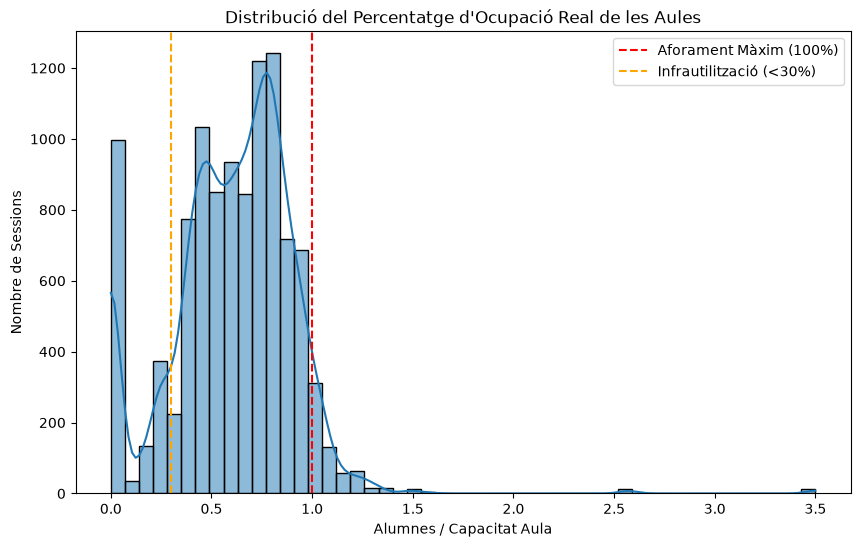

In [3]:
# 3. Infrautilització d'espais
# Considerem infrautilització si els alumnes són menys del 30% de la capacitat de l'aula
df_merge['pct_ocupacio'] = df_merge['alumnes'] / df_merge['capacitat']
infrautilitzades = df_merge[df_merge['pct_ocupacio'] < 0.3]

print(f"Total de sessions amb aules infrautilitzades (<30% ocupació): {len(infrautilitzades)}")

plt.figure(figsize=(10, 6))
sns.histplot(df_merge['pct_ocupacio'], bins=50, kde=True)
plt.axvline(1.0, color='red', linestyle='--', label='Aforament Màxim (100%)')
plt.axvline(0.3, color='orange', linestyle='--', label='Infrautilització (<30%)')
plt.title("Distribució del Percentatge d'Ocupació Real de les Aules")
plt.xlabel("Alumnes / Capacitat Aula")
plt.ylabel("Nombre de Sessions")
plt.legend()
plt.show()


C:\Users\arnau\AppData\Local\Temp\ipykernel_26380\4162484640.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sessions_dia.index, y=sessions_dia.values, palette='Blues_d')


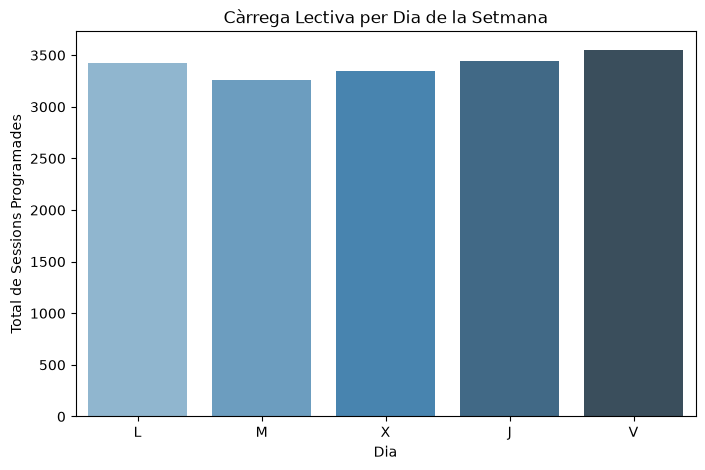

In [4]:
# 4. Càrrega lectiva per dia de la setmana
sessions_dia = sessions.groupby('dia').size().reindex(['L', 'M', 'X', 'J', 'V'])

plt.figure(figsize=(8, 5))
sns.barplot(x=sessions_dia.index, y=sessions_dia.values, palette='Blues_d')
plt.title("Càrrega Lectiva per Dia de la Setmana")
plt.xlabel("Dia")
plt.ylabel("Total de Sessions Programades")
plt.show()


C:\Users\arnau\AppData\Local\Temp\ipykernel_26380\2892130222.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sense_aula_tipus.values, y=sense_aula_tipus.index, palette='Reds_r')


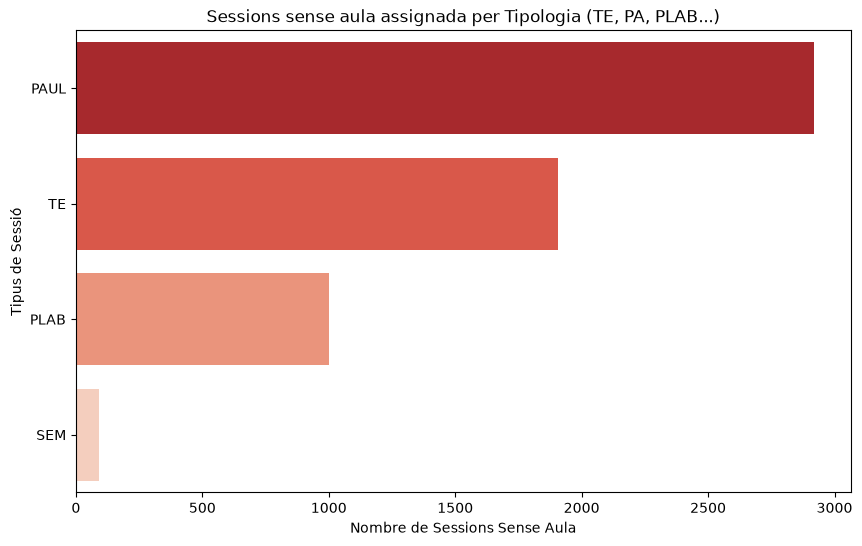

In [5]:
# 5. Sessions sense aula per tipologia
sense_aula = sessions[sessions['aula_partida'].isna()]

sense_aula_tipus = sense_aula.groupby('tipus').size().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=sense_aula_tipus.values, y=sense_aula_tipus.index, palette='Reds_r')
plt.title("Sessions sense aula assignada per Tipologia (TE, PA, PLAB...)")
plt.xlabel("Nombre de Sessions Sense Aula")
plt.ylabel("Tipus de Sessió")
plt.show()
